# 15-T800足底调试检查


## 1. 本课主题：初始高度非常重要

本篇对应《具身智能机器人实战》第 15 节《T800 足底调试检查》，副标题为“初始高度非常重要”。上一节强调用日志分析仿真问题，本节把排查位置前移：机器人开始运动前，先检查它以什么姿态、在什么高度进入仿真。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/15_T800足底调试检查.pptx` 全部 4 页：第 2 页提醒先检查“出场环境”，第 3 页用悬空和脚踝受限的类比说明问题，第 4 页为品牌结束页。

课件没有提供具体初始高度、配置文件位置或修改代码。下面先整理原课的排查思路，再用“工程补充”说明足底与地面应该怎样检查。未转录配套视频 `15_T800机器人初始化高度设置.mp4`，也未读取网盘中的 `code.zip`。


## 2. 机器人倒下后，先检查出场环境

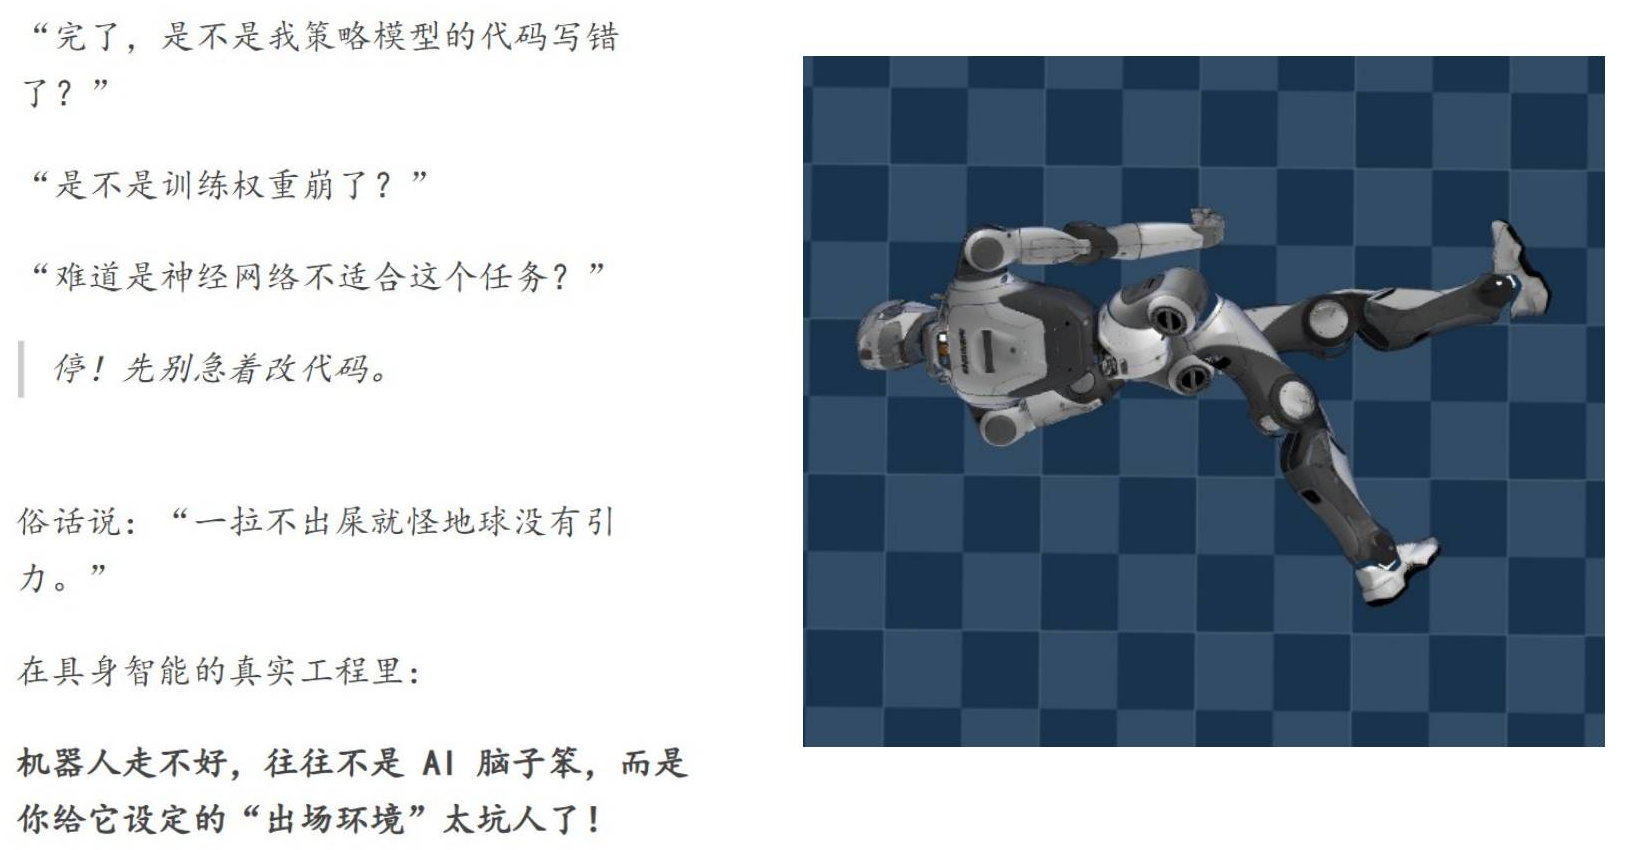

*原课件第 2 页：面对机器人倒下的现象，先别急着修改策略代码，应检查给机器人设定的“出场环境”。*

看到机器人走不好，容易先怀疑策略代码写错、训练权重出问题，或者神经网络不适合这个任务。课件在列出这些疑问后提醒：**先别急着改代码，先检查初始环境是否合理。**

策略要通过机器人的身体与地面相互作用，才能形成预期运动。如果开始时的高度或接触状态已经不合适，后续表现就可能偏离预期。排查时，应把初始条件也作为待检查的对象，不能仅凭倒下的画面判断策略失效。

右侧 T800 画面展示了运动异常的现象。该页没有配套状态记录，不能据此认定这次倒下已经查明是高度问题；它用于引出“先查出场环境”的思路。


## 3. 两个类比：悬空出场与脚踝固定

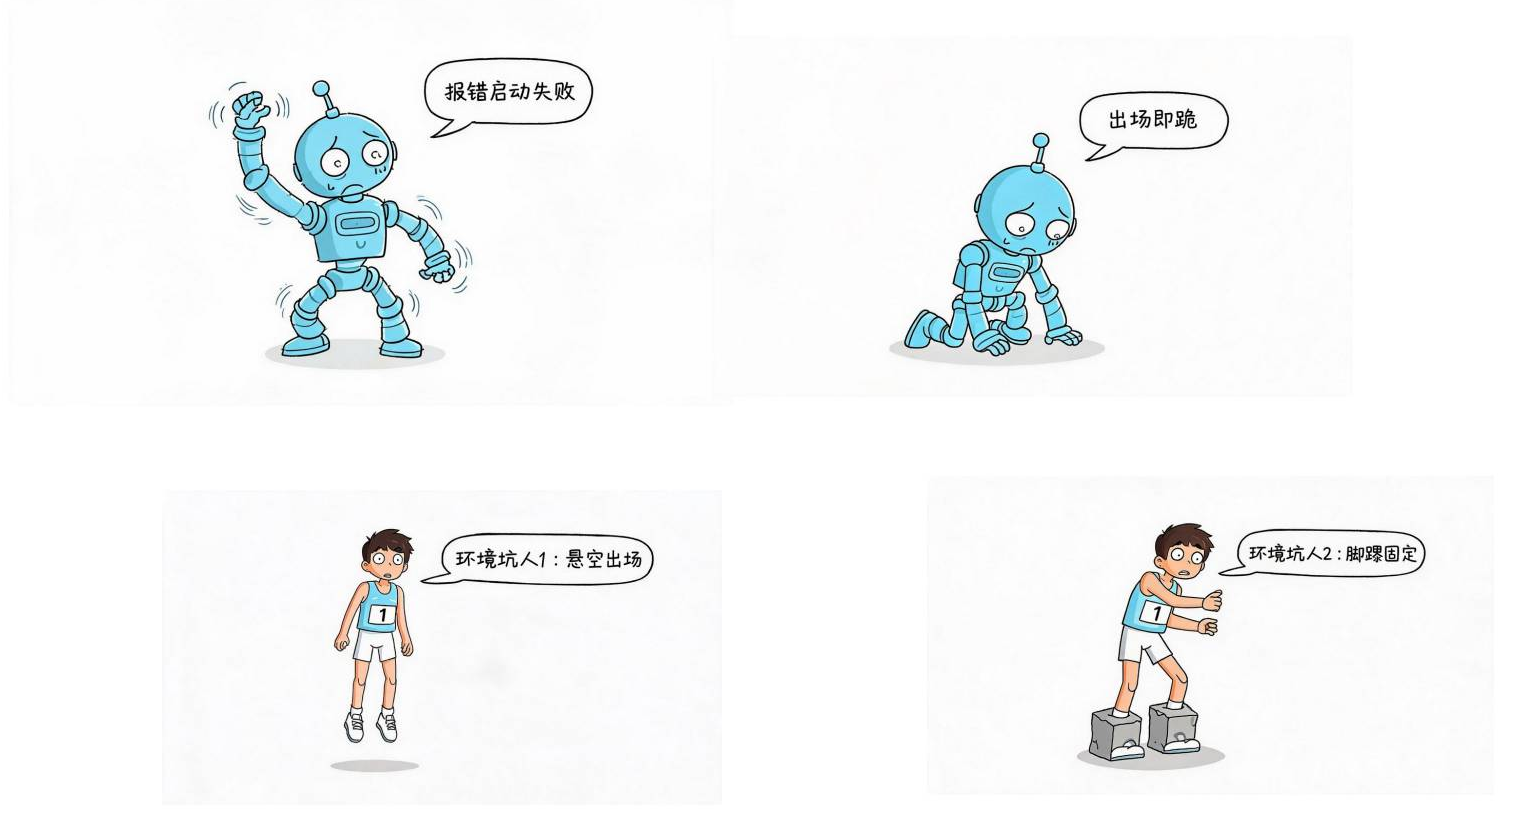

*原课件第 3 页：上方列出“报错启动失败”“出场即跪”的异常现象，下方用“悬空出场”和“脚踝固定”说明不合适的运动条件。*

第一个类比是让运动员悬空出场。脚没有获得地面支撑，即使已经准备好运动，也无法按正常站立条件起步。本课借此提醒：机器人初始化后，要看足底是否处于预期的接地状态。

第二个类比是把运动员的脚踝固定住。身体想运动，足部却受到不合适的限制，动作同样难以完成。检查机器人时，也要关注足部是否存在异常约束或接触。

这两个类比共同强调：初始条件会影响运动的起点。应先确认身体能够按预期与地面接触，再继续分析策略输出和控制参数。

**工程补充：**结合本课的初始高度主题，悬空可用于理解初始位置过高、足底离地的情形；位置过低则可能使足部碰撞几何嵌入地面，产生不合理的初始接触。图中的“脚踝固定”是类比，不能据此认定课程模型确实设置了固定关节，也不能把所有启动报错都归因于高度。


## 4. 工程补充：检查足底与地面的相对位置

下面是对当前检查任务的简短补充，不是课件提供的配置步骤。检查时应结合实际场景模型和初始化代码，不直接套用一个未经核对的高度值。

1. **先确认初始姿态。**明确初始化时身体朝向和腿部关节角；这些量会影响足底位置。同一个根部高度，配合不同屈膝程度，足底与地面的关系也可能不同。
2. **检查左右足与地面。**查看两只脚的实际碰撞几何相对地面的位置，分辨明显悬空、合理接触和明显嵌入。显示网格与碰撞几何可能不同，不能只看机器人外观是否“踩到了地板”。
3. **调整后重新初始化核对。**小幅调整实际控制根部初始高度的设置，恢复相同姿态后再比较，避免把已经倒下后的状态当作新起点。
4. **观察开始阶段的变化。**结合上一节的日志思路，检查身体高度、姿态和接触变化，确认是否一开始就下落、被接触作用顶起或倒下，再继续定位控制环节。

对于预期从站立开始的场景，检查目标是让足底处于合理支撑条件，避免明显悬空或深度嵌入。合适的高度取决于模型、地面、碰撞几何和初始姿态；修正这些初始条件后，还需要实际运行观察，才能判断机器人是否稳定。


## 5. 本课检查

完成本节，应能说明为什么机器人出场就倒下时需要先查初始环境，辨认悬空与足部受限两类问题，并解释为什么只看根部高度数值还不足以确认足底接触是否合理。

本篇已覆盖课件的排查提醒和两组示意图。已读取的课件未给出适用于 T800 的具体高度值和修改方法，本篇没有推定这些配置，也没有执行仿真或验证站立、行走效果。
